# Mixture Density Networks for Stellar Lithium Abundances

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 15 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://tingyuansen.github.io/statml/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Two stars with the same temperature and age can differ in their lithium abundance. A prediction of the lithium abundance from these two properties therefore needs a range of values and not one number. A standard neural network predicts one number. With the squared error, this number is the mean of the possible outputs (Section 15.12). This mean gives the center of the scatter but not its width.

Protons destroy lithium at temperatures above about 2.5 million kelvin. A star therefore keeps lithium only in its cool outer convection zone, and it loses lithium when convection carries it to hotter layers. We usually measure the lithium of a star by A(Li), which is 12 plus the base-10 logarithm of the lithium to hydrogen number ratio. The unit is the dex, and one dex is a factor of 10.

A(Li) depends on the effective temperature $T_{\rm eff}$, because cooler stars have deeper convection zones and destroy more lithium. It also falls with the age $\tau$ of the star. Other properties change the depletion, such as the rotation of the star, its magnetic activity, its accretion history and its metallicity. Stars with similar temperatures and ages can therefore differ in lithium by a factor of several.

A Mixture Density Network (MDN) predicts a probability density and not one number (Section 15.12). A neural network computes the weights, means and widths of a Gaussian mixture from the inputs (Section 11.5). We train it by maximum likelihood (Chapters 4 and 7). The network then models the conditional density $p(\text{A(Li)}|T_{\rm eff}, \tau)$. The hidden properties of the stars appear as its width and its shape.

We first train an MDN on the two moons, a simulated relation in which some inputs have two outputs. We then train it on the temperature, age and lithium abundance of stars in open clusters, where all stars of a cluster share one age. We compare the conditional densities with the stars, and we plot its predictions for many ages.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Python programming with NumPy, matplotlib and PyTorch (Tutorial 15a)
- Neural networks, including feedforward networks, activation functions and gradient-based training (Chapter 15)
- Gaussian mixture models (Chapter 11)
- Maximum likelihood estimation (Chapters 4 and 7)

### Learning Objectives

After this tutorial you can do the following.

- Build a neural network whose output is a Gaussian mixture and not a single value
- Explain how the network sets the weights, means and widths of the mixture and keeps them valid
- Train the network with a numerically stable negative log-likelihood
- Explain why one predicted value fails for a one-to-many relation
- Read a conditional density and compare it with the data
- Read the predictions of the network at many ages

We begin by importing the libraries and setting the plot style.

In [1]:
# Import the libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Colorbar with the height of its panel
def colorbar(im, ax, label=None):
    cax = make_axes_locatable(ax).append_axes("right", size="5%", pad=0.1)
    return plt.colorbar(im, cax=cax, label=label)

# Set the random seed for reproducibility
_ = torch.manual_seed(42)

%matplotlib inline

## The Two-Moons Dataset

We first test the method on the two moons, a simulated relation that shows the problem in its simplest form. The data are two interleaved half circles with noise. Each $x$ between 0 and 1 has two values of $y$, one on the upper moon and one on the lower moon.

No function $y = f(x)$ describes this one-to-many relation, however complex it is. A standard neural network gives one $y$ for each $x$. Trained with the squared error, it predicts the mean of the two values, which lies between the moons (Section 15.12). This mean minimizes the squared error and describes neither moon.

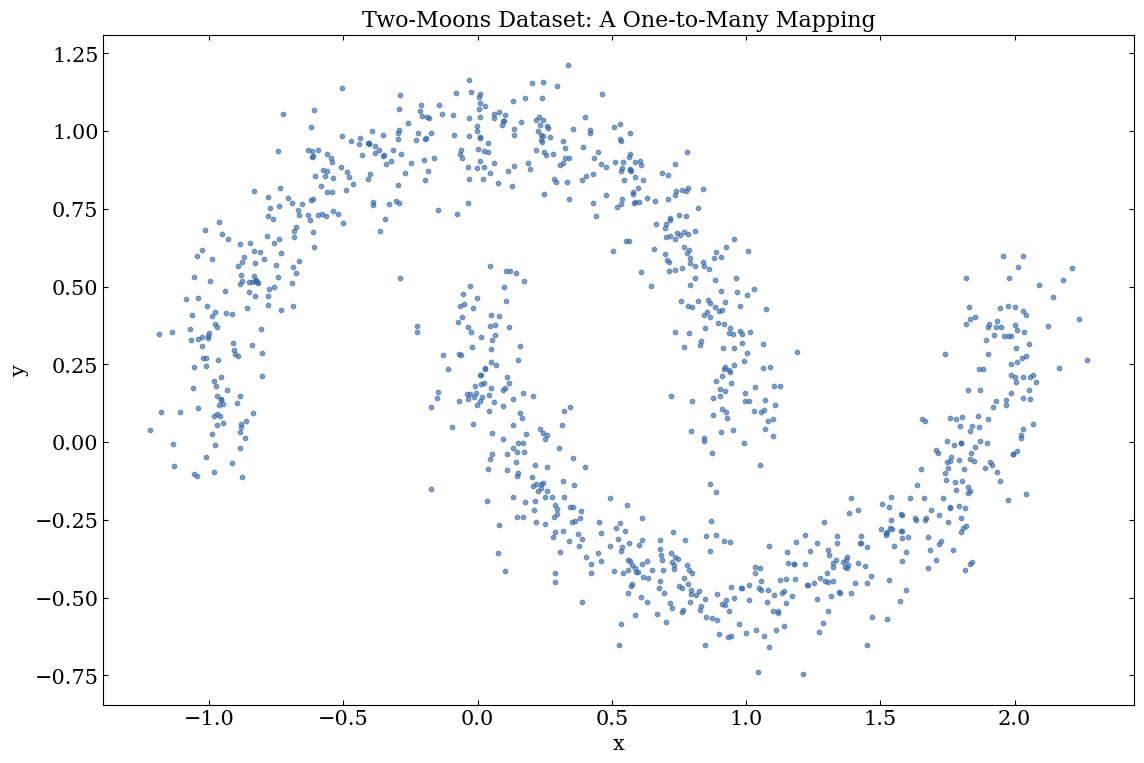

In [2]:
def make_two_moons(n_samples, noise, random_state):
    """Return n_samples points on two interleaved half circles, with Gaussian noise."""
    rng = np.random.RandomState(random_state)
    n_upper = n_samples // 2
    n_lower = n_samples - n_upper

    # The upper moon is a half circle, and the lower moon is a shifted half circle
    angle_upper = np.linspace(0, np.pi, n_upper)
    angle_lower = np.linspace(0, np.pi, n_lower)
    X = np.vstack([np.append(np.cos(angle_upper), 1 - np.cos(angle_lower)),
                   np.append(np.sin(angle_upper), 1 - np.sin(angle_lower) - 0.5)]).T

    # Shuffle the points and add the noise
    X = X[rng.permutation(n_samples)]
    return X + rng.normal(scale=noise, size=X.shape)

# Generate two interleaved half circles with added noise
X = make_two_moons(n_samples=1000, noise=0.1, random_state=42)

# Extract the x and y coordinates
x_train = X[:, 0]
y_train = X[:, 1]

# Plot the two-moons dataset
plt.figure(figsize=(13.3, 8.7))
plt.scatter(x_train, y_train, s=10, alpha=0.6)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Two-Moons Dataset: A One-to-Many Mapping')
plt.show()

We train a standard network with the squared error on the two moons. It has two hidden layers of 20 neurons and one output. We plot its prediction and print the prediction at $x = 0.5$ next to the mean of the points of each moon near this $x$.

Prediction at x = 0.5: 0.25
Mean of the points of the upper moon: 0.88, of the lower moon: -0.36


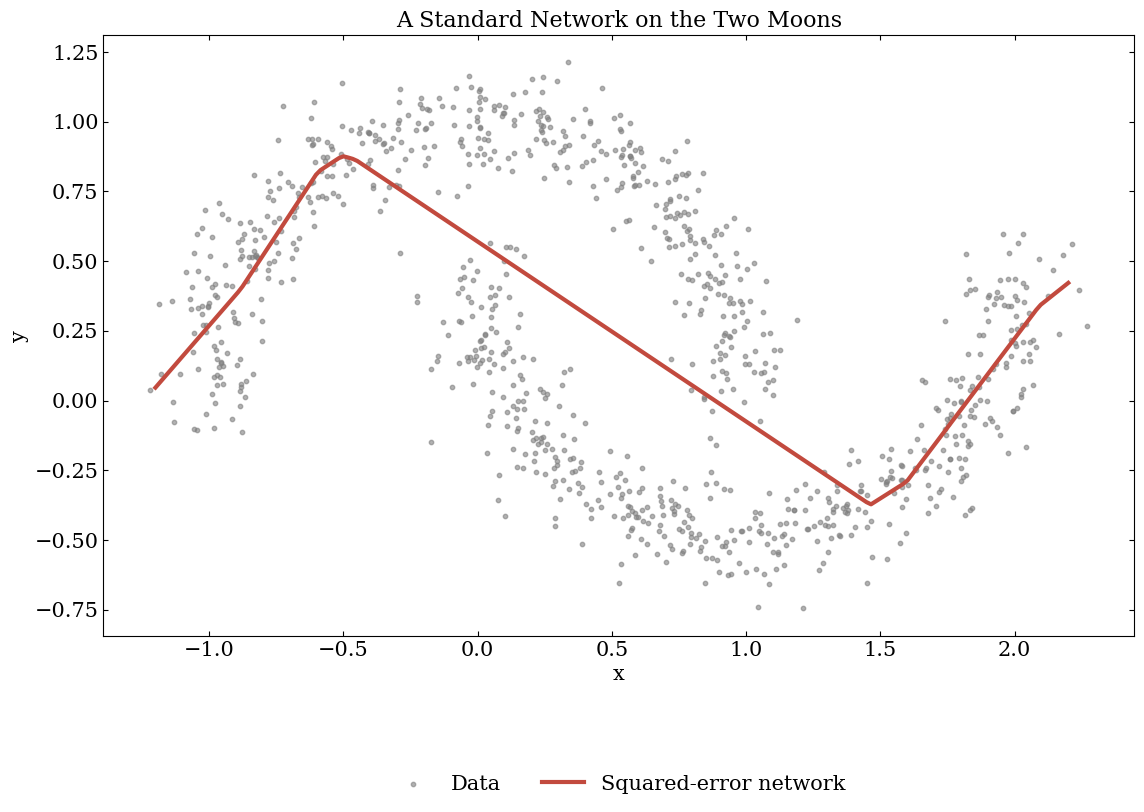

In [3]:
# Keep the random state, so that this test does not change the later runs
rng_state = torch.get_rng_state()
_ = torch.manual_seed(0)

# A standard network with two hidden layers of 20 neurons, trained with the squared error
x_moon = torch.from_numpy(x_train).float().reshape(-1, 1)
y_moon = torch.from_numpy(y_train).float().reshape(-1, 1)
mse_net = nn.Sequential(nn.Linear(1, 20), nn.ReLU(), nn.Linear(20, 20), nn.ReLU(), nn.Linear(20, 1))
optimizer = torch.optim.Adam(mse_net.parameters(), lr=1e-3)
for _ in range(2000):
    loss = nn.functional.mse_loss(mse_net(x_moon), y_moon)
    optimizer.zero_grad()  # Reset the gradients
    loss.backward()  # Compute the gradients by backpropagation
    optimizer.step()  # Update the network parameters
torch.set_rng_state(rng_state)

# Prediction on a grid of x, and at x = 0.5
x_line = torch.linspace(-1.2, 2.2, 200).reshape(-1, 1)
with torch.no_grad():
    y_line = mse_net(x_line).numpy().ravel()
    y_half = mse_net(torch.tensor([[0.5]])).item()

# Mean of the points of each moon within 0.05 of x = 0.5
near_half = np.abs(x_train - 0.5) < 0.05
upper = y_train[near_half & (y_train > 0.25)].mean()
lower = y_train[near_half & (y_train <= 0.25)].mean()
print(f"Prediction at x = 0.5: {y_half:.2f}")
print(f"Mean of the points of the upper moon: {upper:.2f}, of the lower moon: {lower:.2f}")

# Plot the data and the prediction
plt.figure(figsize=(13.3, 7.8))
plt.scatter(x_train, y_train, s=10, alpha=0.6, color='gray', label='Data')
plt.plot(x_line.numpy().ravel(), y_line, color='C3', linewidth=3, label='Squared-error network')
plt.xlabel('x')
plt.ylabel('y')
plt.title('A Standard Network on the Two Moons')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.show()

The prediction at $x = 0.5$ is close to the average of the two moons, so it describes neither moon. It lies in the empty space between them. The network gives one value, without a width. A model of this relation must give a density of $y$ for each $x$.

## The Mathematical Formulation of Mixture Density Networks

An MDN replaces a point prediction by a probability density. It does not learn a function $\mathbf{y} = f(\mathbf{x})$. It learns the conditional density $p(\mathbf{y}|\mathbf{x})$ (Section 15.12). The density can then show both the scatter and several groups of values in the data.

### Gaussian Mixture Models as Output Densities

An MDN models the conditional density as a mixture of Gaussians,

$$p(\mathbf{y}|\mathbf{x}) = \sum_{k=1}^K \pi_k(\mathbf{x}) \mathcal{N}(\mathbf{y}|\boldsymbol{\mu}_k(\mathbf{x}), \boldsymbol{\Sigma}_k(\mathbf{x})).$$

Each component of this mixture has three parameters that depend on the input $\mathbf{x}$.

1. The mixture weights $\pi_k(\mathbf{x})$ are the relative weights of the components, with $\sum_k \pi_k(\mathbf{x}) = 1$.
2. The means $\boldsymbol{\mu}_k(\mathbf{x})$ are the centers of the components.
3. The covariances $\boldsymbol{\Sigma}_k(\mathbf{x})$ set the spread and the shape of the components. We often simplify them to diagonal or spherical covariances.

A neural network computes these parameters as functions of the input. The density then changes smoothly over the input space and follows the local structure of the data.

### Network Architecture and Output Constraints

The network must output the parameters of the mixture, and these parameters have to be valid. The weights must form a probability distribution, and the widths must be positive. The output layer therefore transforms the raw numbers of the network. The hidden layers use the ReLU activation (Section 15.5).

For a mixture with $K$ components and $D$-dimensional outputs, the network must produce the following.

- $K$ mixture weights, which form a valid probability distribution
- $K \times D$ mean values, which are unconstrained
- The covariance parameters, which must give positive definite covariances

The architecture is a standard feedforward network until the output layer, where we must handle the constraints with care. A softmax transformation makes the mixture weights positive and sum to 1 (Section 15.12),

$$\pi_k(\mathbf{x}) = \frac{\exp(z_k(\mathbf{x}))}{\sum_{j=1}^K \exp(z_j(\mathbf{x}))},$$

where $z_k(\mathbf{x})$ are the raw network outputs for the mixture weights, called logits. For simplicity we use diagonal covariances. In this tutorial the output $y$ is one number, so each covariance is a variance $\sigma_k^2(\mathbf{x})$. The network outputs $\ln \sigma_k$, and the exponential function makes $\sigma_k$ positive. The output layer therefore has $3K$ numbers, the $K$ means, the $K$ values of $\ln \sigma_k$ and the $K$ logits.

In [4]:
class MDN(nn.Module):
    """Mixture Density Network for conditional density estimation."""
    def __init__(self, n_inputs=1, n_hidden=20, n_gaussians=2):
        super().__init__()

        self.n_gaussians = n_gaussians

        # Two hidden layers of a standard feedforward network
        self.fc1 = nn.Linear(n_inputs, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_hidden)

        # The output layer gives three numbers for each Gaussian component
        # These are a mean, a log standard deviation and a logit of the mixture weight
        self.fc3 = nn.Linear(n_hidden, n_gaussians * 3)

    def forward(self, x):
        # Extract features with the hidden layers and the ReLU activation
        h = torch.relu(self.fc1(x))
        h = torch.relu(self.fc2(h))

        # Compute the mixture parameters
        params = self.fc3(h)

        # Split the parameters by type
        mu = params[:, :self.n_gaussians]
        log_sigma = params[:, self.n_gaussians:2*self.n_gaussians]
        logit_pi = params[:, 2*self.n_gaussians:]

        # Apply the constraints
        sigma = torch.exp(log_sigma)  # Make the standard deviations positive
        pi = torch.softmax(logit_pi, dim=1)  # Make the weights sum to 1

        return mu, sigma, pi

## Training Mixture Density Networks

We train an MDN by maximum likelihood (Chapters 4 and 7). The output $y_i$ is one number here. For $N$ pairs $(\mathbf{x}_i, y_i)$ we seek the network parameters $\mathbf{w}$ that maximize the likelihood of the data under the conditional densities of the network,

$$L(\mathbf{w}) = \prod_{i=1}^N p(y_i|\mathbf{x}_i, \mathbf{w}).$$

The logarithm turns this product into a sum, which avoids underflow, and gives the log-likelihood (Section 15.12),

$$\ell(\mathbf{w}) = \ln L(\mathbf{w}) = \sum_{i=1}^N \ln \left[ \sum_{k=1}^K \pi_k(\mathbf{x}_i) \mathcal{N}(y_i|\mu_k(\mathbf{x}_i), \sigma_k^2(\mathbf{x}_i)) \right].$$

We minimize the negative log-likelihood, which is our loss function. In the code we take the mean over the points and not the sum. The size of the gradient then does not depend on the number of points (Section 15.3).

The inner sum over the components can underflow when every term is small. The code therefore adds the terms with the log-sum-exp function. Let $a_k = \ln\pi_k + \ln\mathcal{N}(y|\mu_k, \sigma_k^2)$ be the logarithm of the term of component $k$, and let $m$ be the largest of the $a_k$. Then

$$\ln \sum_{k=1}^K e^{a_k} = m + \ln \sum_{k=1}^K e^{a_k - m}.$$

The exponentials on the right are at most 1, and one of them is exactly 1, so the sum cannot underflow. The method `log_prob` of `torch.distributions.Normal` gives the log of the Gaussian density of each component.

The optimization is the same as for a standard neural network. Backpropagation computes the gradients through the mixture parameters and through the weights of the network (Section 15.4). The difference lies in the loss function. It measures how well the conditional densities explain the data, and not the distance to point predictions.

In [5]:
def mixture_log_prob(y, mu, sigma, pi):
    """Logarithm of the mixture density at y."""

    # Create a Gaussian distribution for each component
    gaussians = torch.distributions.Normal(mu, sigma)

    # Compute the log probability of y under each component
    log_prob = gaussians.log_prob(y)

    # Weight each component by its mixture weight
    # In the logarithm the product of weight and density is the sum log(pi) + log(N)
    weighted_log_prob = log_prob + torch.log(pi)

    # Sum over the components with the log-sum-exp, which stays numerically stable
    return torch.logsumexp(weighted_log_prob, dim=1)

def mdn_loss_fn(y_true, mu, sigma, pi):
    """Negative log-likelihood of the mixture, averaged over the batch."""
    return -torch.mean(mixture_log_prob(y_true, mu, sigma, pi))

We train the model with Adam on mini-batches of 64 points, as in Tutorial 15a (Section 15.3). We print the loss of all points at a few epochs. One epoch is one pass through the points, and the printed loss belongs to the weights at the end of that epoch.

In [6]:
def train_mdn(model, x, y, n_epochs, lr, checkpoints):
    """Train the MDN with Adam on mini-batches of 64 points."""

    # Create a data loader for mini-batches
    dataloader = DataLoader(TensorDataset(x, y), batch_size=64, shuffle=True)

    # Configure the optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Training loop
    for epoch in range(1, n_epochs + 1):
        for x_batch, y_batch in dataloader:
            # Forward pass
            mu, sigma, pi = model(x_batch)
            loss = mdn_loss_fn(y_batch, mu, sigma, pi)

            # Backward pass and optimizer step
            optimizer.zero_grad()  # Reset the gradients
            loss.backward()  # Compute the gradients by backpropagation
            optimizer.step()  # Update the network parameters

        # Report the loss of all points at the current weights
        if epoch in checkpoints:
            with torch.no_grad():
                full_loss = mdn_loss_fn(y, *model(x)).item()
            print(f'Epoch {epoch:4d}, loss {full_loss:.4f}')

## Application to the Two-Moons Dataset

With the MDN and its loss function defined, we train the model on the two moons. We use two components, one for each moon. The network has two hidden layers of 20 neurons. We train for 1000 epochs with the learning rate 0.001.

In [7]:
# Convert the data to PyTorch tensors with one column
x = torch.from_numpy(x_train).float().reshape(-1, 1)
y = torch.from_numpy(y_train).float().reshape(-1, 1)

# Create an MDN with 2 Gaussian components
model = MDN(n_inputs=1, n_hidden=20, n_gaussians=2)

# Train for 1000 epochs and print the loss at three epochs
train_mdn(model, x, y, n_epochs=1000, lr=1e-3, checkpoints=(1, 100, 1000))

Epoch    1, loss 1.0025
Epoch  100, loss -0.0333
Epoch 1000, loss -0.1361


## Visualizing the Learned Densities

We look at how the MDN represents the two moons. The network gives the weights, means and standard deviations of the two components for every $x$. We plot the means with a band of one standard deviation, over a range of $x$ wider than the range of the data. The lines outside the range of the data are extrapolations.

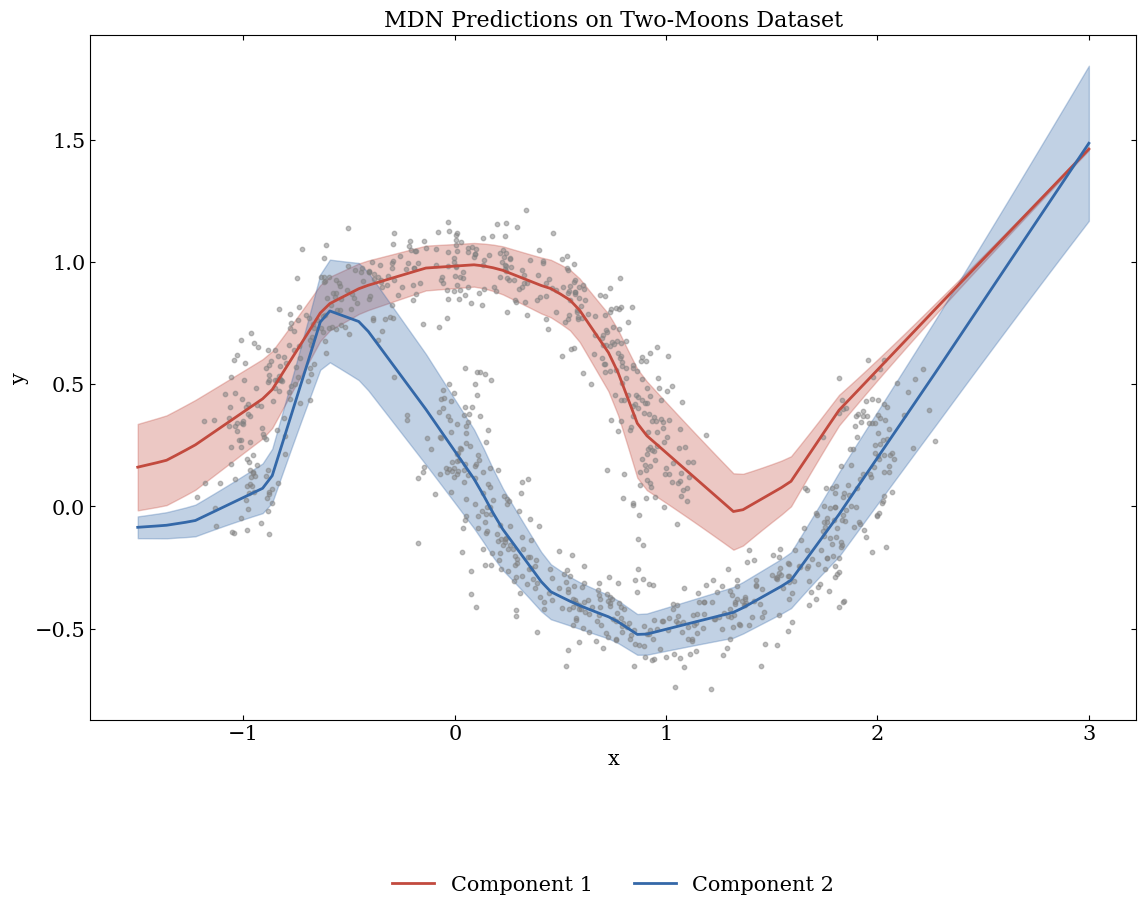

In [8]:
# Generate predictions over the input range
x_test = torch.linspace(-1.5, 3, 100).reshape(-1, 1)
mu_pred, sigma_pred, pi_pred = model(x_test)

# Convert to numpy for plotting
x_test_np = x_test.detach().numpy()  # detach removes the gradient information
mu_pred_np = mu_pred.detach().numpy()  # the means
sigma_pred_np = sigma_pred.detach().numpy()  # the standard deviations
pi_pred_np = pi_pred.detach().numpy()  # the mixture weights

# Plot the predicted Gaussian components
plt.figure(figsize=(13.5, 8.9))

# Plot each Gaussian component
colors = ['C3', 'C0']
for k in range(2):
    # Plot the mean
    plt.plot(x_test_np, mu_pred_np[:, k], color=colors[k],
             label=f'Component {k+1}', linewidth=2)

    # Plot the band of one standard deviation
    plt.fill_between(x_test_np.ravel(),
                     mu_pred_np[:, k] - sigma_pred_np[:, k],
                     mu_pred_np[:, k] + sigma_pred_np[:, k],
                     alpha=0.3, color=colors[k])

# Overlay the original data
plt.scatter(x_train, y_train, s=10, alpha=0.5, color='gray')

# Labels and legend
plt.xlabel('x')
plt.ylabel('y')
plt.title('MDN Predictions on Two-Moons Dataset')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.show()

Between $x = 0$ and $x = 1$, where both moons exist, the two component means follow the upper and the lower moon. The width of each band is about the width of the moon that it follows. We plot the mixture weights next, which say how much each component contributes at each $x$.

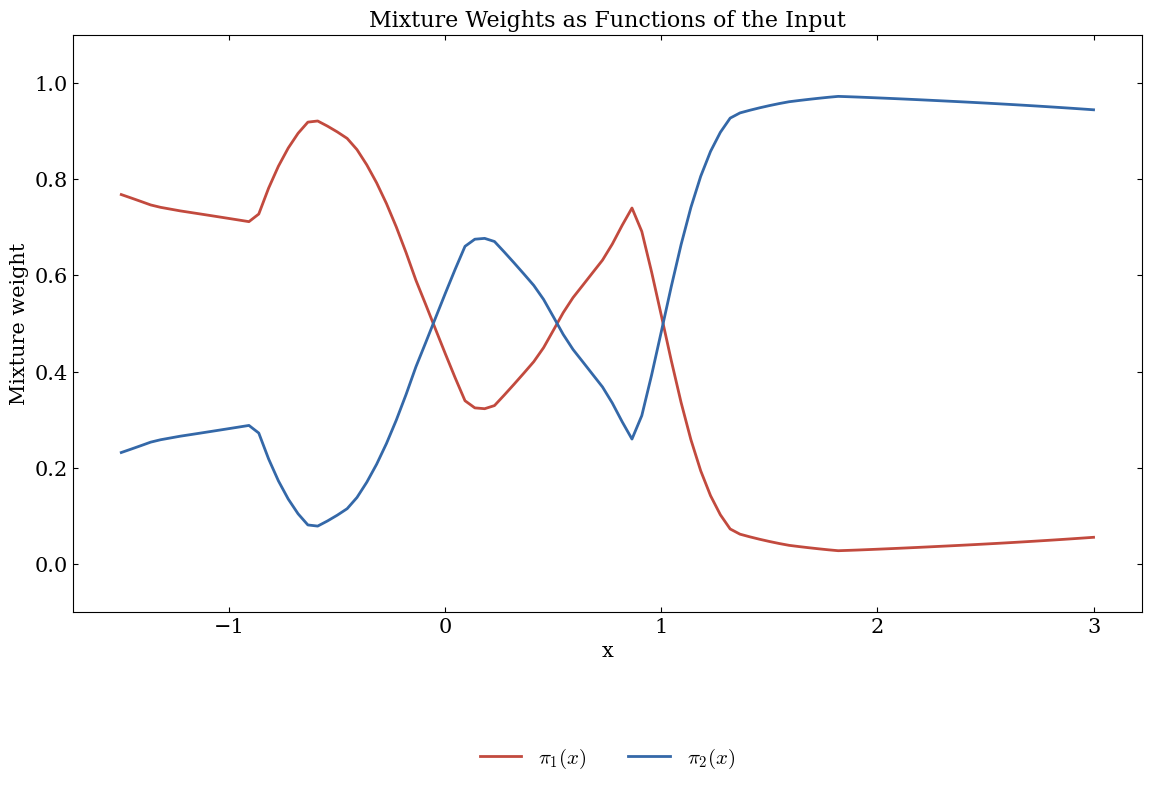

In [9]:
# Plot how the mixture weights change with the input
plt.figure(figsize=(13.8, 7.5))

for k in range(2):
    plt.plot(x_test_np, pi_pred_np[:, k], color=colors[k],
             label=r'$\pi_{}(x)$'.format(k+1), linewidth=2)

# Labels and legend
plt.xlabel('x')
plt.ylabel('Mixture weight')
plt.title('Mixture Weights as Functions of the Input')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.ylim(-0.1, 1.1)
plt.show()

Where both moons exist, both weights are large. Where only one moon exists, one component carries most of the weight. The weights change with $x$, as the means do, so the whole density changes with the input.

The means, widths and weights together give the density $p(y|x)$, which is the output of the MDN. We plot it for the moons at $x = -0.5$, 0.5 and 1.5. The thin black curves are the two weighted components, and the short vertical lines at the bottom mark the points within 0.1 of each $x$.

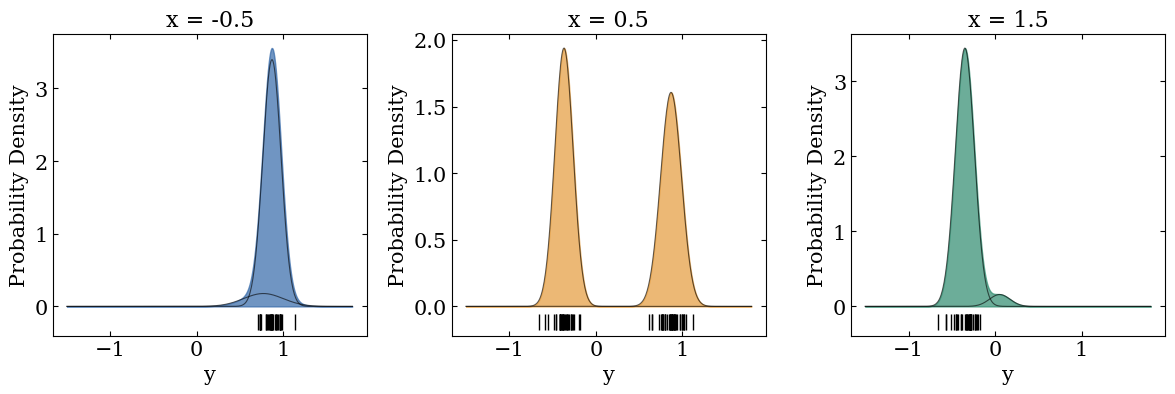

In [10]:
# The density p(y|x) of the two-component MDN at three values of x
y_axis = torch.linspace(-1.5, 1.8, 400).reshape(-1, 1)
plt.figure(figsize=(12, 4.2))
for i, x_value in enumerate((-0.5, 0.5, 1.5)):
    with torch.no_grad():
        mu_x, sigma_x, pi_x = model(torch.tensor([[x_value]]))
        density = torch.exp(mixture_log_prob(y_axis, mu_x, sigma_x, pi_x)).numpy()

    # Points of the data near this x
    near_x = y_train[np.abs(x_train - x_value) < 0.1]

    # Plot the density and mark the points
    plt.subplot(1, 3, i + 1)
    components = (pi_x * torch.exp(torch.distributions.Normal(mu_x, sigma_x).log_prob(y_axis))).numpy()
    plt.plot(y_axis.numpy().ravel(), components, color='black', linewidth=0.8, alpha=0.6)
    plt.fill_between(y_axis.numpy().ravel(), density, alpha=0.7, color=f'C{i}')
    plt.plot(near_x, np.full(len(near_x), -0.06 * density.max()), '|', color='black', markersize=12)
    plt.xlabel('y')
    plt.ylabel('Probability Density')
    plt.title(f'x = {x_value}')

plt.tight_layout()
plt.show()

At $x = 0.5$ both moons exist, and each component forms one peak. At $x = 1.5$ only the lower moon exists, and one component carries almost all the weight. At $x = -0.5$ only the upper moon exists, and both components lie on it, one with a small weight.

## The Lithium Data

We now turn to the lithium abundance of stars. Two stars with the same temperature and age can differ in A(Li). Here we do not expect two branches as for the moons. We ask for the mean, the width and the shape of the density.

The sample is part of the open-cluster sample of [Sun et al. (2025)](https://ui.adsabs.harvard.edu/abs/2025ApJ...978..107S/abstract), who also train a mixture density network on it. It holds the stars of five clusters, the Pleiades (0.10 Gyr), M48 (0.42 Gyr), the Hyades and Praesepe (0.65 Gyr) and NGC 3960 (1.00 Gyr). The stars of an open cluster formed from one cloud at nearly the same time, so they share an age. The age comes from fitting stellar evolution models to the colors and brightnesses of the stars of the cluster. It is usually more precise than the age of an isolated star.

The Hyades and Praesepe share one age, so the data hold only four ages. The ages are in Gyr, and 1 Gyr is one billion years.

In [11]:
# Load the lithium abundance dataset of the open clusters
data = np.load('../data/dataset_lithium_abundance.npz')

# Extract the age in Gyr, the effective temperature in K and the abundance A(Li)
age = data['age']
teff = data['teff']
ALi = data['ALi']

# Print the number of stars and the temperature range of each cluster
print(f"{len(teff)} stars at {len(np.unique(age))} ages")
for a in np.unique(age):
    t = teff[age == a]  # temperatures of the stars of this cluster
    print(f"Age {a:.2f} Gyr: {len(t)} stars, {t.min()} to {t.max()} K")


358 stars at 4 ages
Age 0.10 Gyr: 112 stars, 4199 to 7700 K
Age 0.42 Gyr: 126 stars, 4350 to 7669 K
Age 0.65 Gyr: 91 stars, 5143 to 7623 K
Age 1.00 Gyr: 29 stars, 5274 to 6733 K


We plot A(Li) against the temperature, colored by the age.

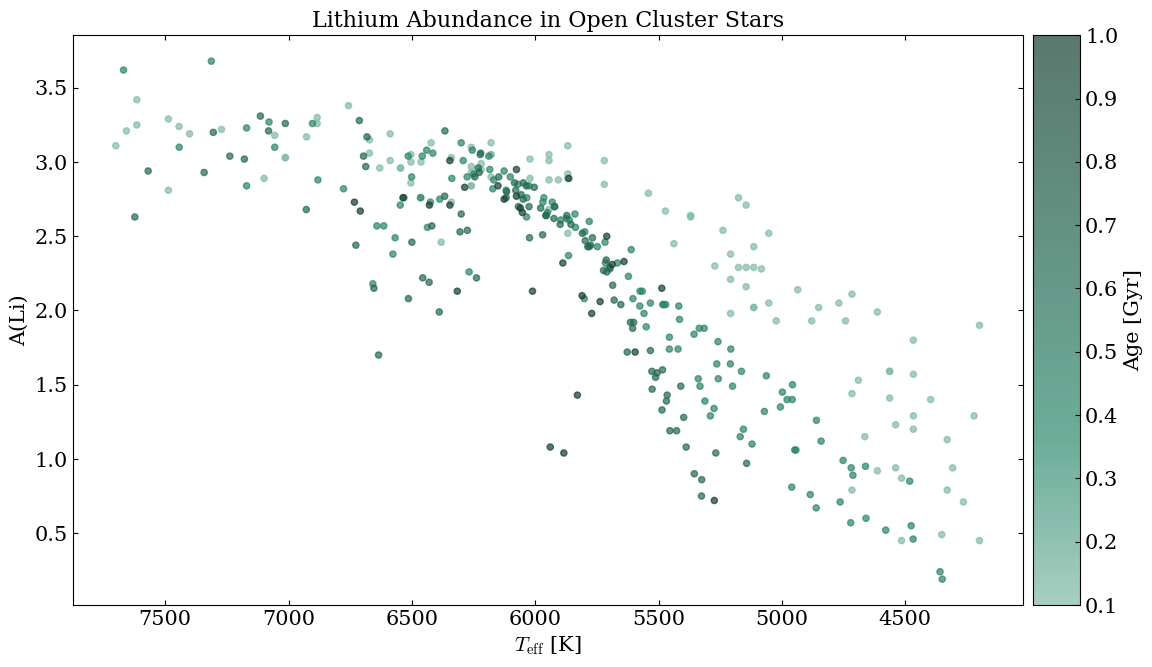

In [12]:
# Visualize the lithium depletion pattern
plt.figure(figsize=(13.0, 7.4))

# Scatter plot colored by age, young light and old dark green as in the book
scatter = plt.scatter(teff, ALi, c=age, cmap=plt.matplotlib.colors.ListedColormap(plt.colormaps['book_green'](np.linspace(0.3, 1, 256))), s=20, alpha=0.7)

# Colorbar for the age
ax = plt.gca()
colorbar(scatter, ax, label='Age [Gyr]')
plt.sca(ax)  # back to the main panel

plt.xlabel(r'$T_{\rm eff}$ [K]')
plt.ylabel('A(Li)')
plt.title('Lithium Abundance in Open Cluster Stars')

# Invert the x axis (astronomical convention, hot stars on the left)
plt.gca().invert_xaxis()

plt.show()

The plot shows three features.

1. **Temperature dependence.** A(Li) decreases toward cooler stars.
2. **Age dependence.** At fixed temperature, older clusters (darker points) tend to have lower abundances than younger clusters (lighter points).
3. **Scatter.** Even at fixed temperature and age, a scatter remains, often of a factor of several. Other properties of the stars cause it, such as the rotation, the magnetic activity, the accretion history and the metallicity.

## Modeling Lithium Abundance with MDNs

We want a model of the conditional density $p(\text{A(Li)}|T_{\rm eff}, \tau)$. An MDN predicts a mixture of Gaussians for each pair of temperature and age. The mixture gives the mean depletion and the scatter at each point, and it can have more than one peak.

The inputs are $T_{\rm eff}$ in units of 1000 K, which is closer to the scale of the age, and the age $\tau$ in Gyr. We use two components, as for the moons, so that the mixture can have a main peak and a tail. The network has two hidden layers of 50 neurons. We train it on all stars with Adam, the learning rate 0.0001 and 5000 epochs. In our tests, the GELU activation and a cosine schedule gave no better fit, so we keep ReLU and a constant rate.

In [13]:
# Prepare the input features, temperature in units of 1000 K and age in Gyr
X = np.column_stack([teff / 1000.0, age])
y = ALi.reshape(-1, 1)
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).float()

# Create an MDN with two Gaussian components
model = MDN(n_inputs=2, n_hidden=50, n_gaussians=2)

# Train for 5000 epochs with a lower learning rate and print the loss at three epochs
train_mdn(model, X_tensor, y_tensor, n_epochs=5000, lr=1e-4, checkpoints=(1, 1000, 5000))


Epoch    1, loss 2.7158
Epoch 1000, loss 0.2764
Epoch 5000, loss -0.0058


## Visualizing Lithium Evolution in Parameter Space

With the trained MDN we can explore how the conditional density changes with temperature and age. We want the mean and the standard deviation of the mixture at each point. A mixture generates a value in two steps. It picks the component $k$ with the probability $\pi_k(\mathbf{x})$, and it then draws $y$ from the Gaussian of that component. With this view, the laws of total expectation and total variance of Chapter 3 give both quantities.

The mean of the mixture is the mean of the component means, weighted by the probability of each component (Section 3.4),

$$\mathbb{E}[y|\mathbf{x}] = \sum_{k=1}^K \pi_k(\mathbf{x}) \mu_k(\mathbf{x}).$$

The variance has two sources (Section 3.8). The first is the spread of $y$ inside a component, $\sigma_k^2$. The second is the spread of the component means around the mean of the mixture, $(\mu_k - \mathbb{E}[y|\mathbf{x}])^2$. Each source is weighted by $\pi_k$,

$$\text{Var}[y|\mathbf{x}] = \sum_{k=1}^K \pi_k(\mathbf{x}) \left[\sigma_k^2(\mathbf{x}) + \left(\mu_k(\mathbf{x}) - \mathbb{E}[y|\mathbf{x}]\right)^2\right].$$

The first term is the width that each component has on its own. The second term is large when the means of the components lie far apart, even if each component is narrow. If all components have the same mean, it is 0, and the variance is the weighted mean of the component variances. We write $\sigma_{\rm A(Li)}$ for the square root of the variance, the total scatter of the mixture at a point.

We first predict at the four ages of the data. For each age we use the temperatures from the coolest to the hottest star of the cluster, so the predictions stay inside the data.

In [14]:
# The four cluster ages
age_grid = np.unique(age)

# For each age, 100 temperatures from the coolest to the hottest star of the cluster
teff_grid = []
for a in age_grid:
    t_low, t_high = teff[age == a].min(), teff[age == a].max()  # temperature range of the cluster
    teff_grid.append(np.linspace(t_low, t_high, 100) / 1000.0)  # in units of 1000 K

def mixture_moments(mu, sigma, pi):
    """Mean and standard deviation of the mixture for each input."""

    # The weighted mean of the means, and the weighted variances plus the weighted spread of the means
    mean = (pi * mu).sum(dim=1)
    var = (pi * (sigma**2 + (mu - mean[:, None])**2)).sum(dim=1)
    return mean, torch.sqrt(var)

# Storage for the predictions
mean_ALi = []
sd_ALi = []

# Generate predictions for each age
with torch.no_grad():
    for age_val, t_grid in zip(age_grid, teff_grid):
        # Create the temperature grid at fixed age
        X_pred = torch.zeros((len(t_grid), 2))
        X_pred[:, 0] = torch.tensor(t_grid)
        X_pred[:, 1] = float(age_val)

        # Get the MDN predictions and the moments of the mixture
        mean, sd = mixture_moments(*model(X_pred))
        mean_ALi.append(mean.numpy())
        sd_ALi.append(sd.numpy())

We plot the predicted mean over the stars, and $\sigma_{\rm A(Li)}$, for each age of a cluster.

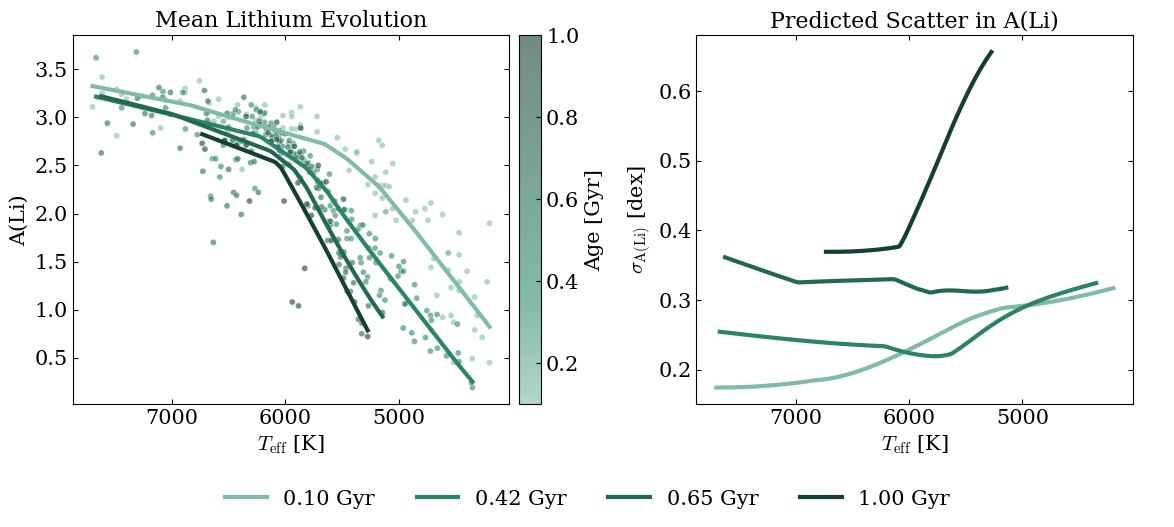

In [15]:
# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.4))

# One color scale for the ages, the same for the stars and the lines, young light and old dark green as in the book
cmap = plt.matplotlib.colors.ListedColormap(plt.colormaps['book_green'](np.linspace(0.3, 1, 256)))
norm = plt.Normalize(age.min(), age.max())

# Left panel, the mean lithium evolution
for age_val, t_grid, mean_row in zip(age_grid, teff_grid, mean_ALi):
    ax1.plot(t_grid * 1000, mean_row, color=cmap(norm(age_val)), linewidth=3)

# Overlay the observed data
scatter1 = ax1.scatter(teff, ALi, c=age, cmap=cmap, norm=norm, s=20,
                       alpha=0.6, edgecolors='white', linewidth=0.5)
ax1.set_xlabel(r'$T_{\rm eff}$ [K]')
ax1.set_ylabel('A(Li)')
ax1.set_title('Mean Lithium Evolution')
ax1.invert_xaxis()

# Colorbar for the age
colorbar(scatter1, ax1, label='Age [Gyr]')

# Right panel, the scatter in the predictions for each age
for age_val, t_grid, sd_row in zip(age_grid, teff_grid, sd_ALi):
    ax2.plot(t_grid * 1000, sd_row, color=cmap(norm(age_val)), linewidth=3)

# Labels and title of the right panel
ax2.set_xlabel(r'$T_{\rm eff}$ [K]')
ax2.set_ylabel(r'$\sigma_{\rm A(Li)}$ [dex]')
ax2.set_title('Predicted Scatter in A(Li)')
ax2.invert_xaxis()

# One legend below both panels for the ages of the lines
handles = [plt.Line2D([0], [0], color=cmap(norm(a)), linewidth=3) for a in age_grid]
fig.legend(handles, [f'{a:.2f} Gyr' for a in age_grid], loc='lower center', ncol=len(age_grid), bbox_to_anchor=(0.5, 0.0))

# Empty axes of the width of the colorbar, so that the two panels have the same size
make_axes_locatable(ax2).append_axes("right", size="5%", pad=0.1).axis('off')

plt.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()


## Predictions at Many Ages

The four lines above show four separate ages. The age is an input of the network, so the MDN gives a prediction at any age. We plot the mean and the scatter for many ages from 0.10 to 1.00 Gyr, to see how they change with the age. All lines use the temperatures where all four clusters have stars, so that every line lies inside the data.

In [16]:
# Ages from 0.10 to 1.00 Gyr in steps of 0.05 Gyr, with the four cluster ages added
ages_band = np.unique(np.round(np.concatenate([np.linspace(0.10, 1.00, 19), age_grid]), 2))

# One temperature range for all ages, where all four clusters have stars, in units of 1000 K
t_grid = np.linspace(max(t[0] for t in teff_grid), min(t[-1] for t in teff_grid), 100)

# The predictions of the network at each age
mean_band, sd_band = [], []
with torch.no_grad():
    for age_val in ages_band:
        X_pred = torch.tensor(np.column_stack([t_grid, np.full(100, age_val)]), dtype=torch.float32)
        mean, sd = mixture_moments(*model(X_pred))
        mean_band.append(mean.numpy())
        sd_band.append(sd.numpy())


We plot the lines with the color of their age. The thick lines are the four cluster ages.

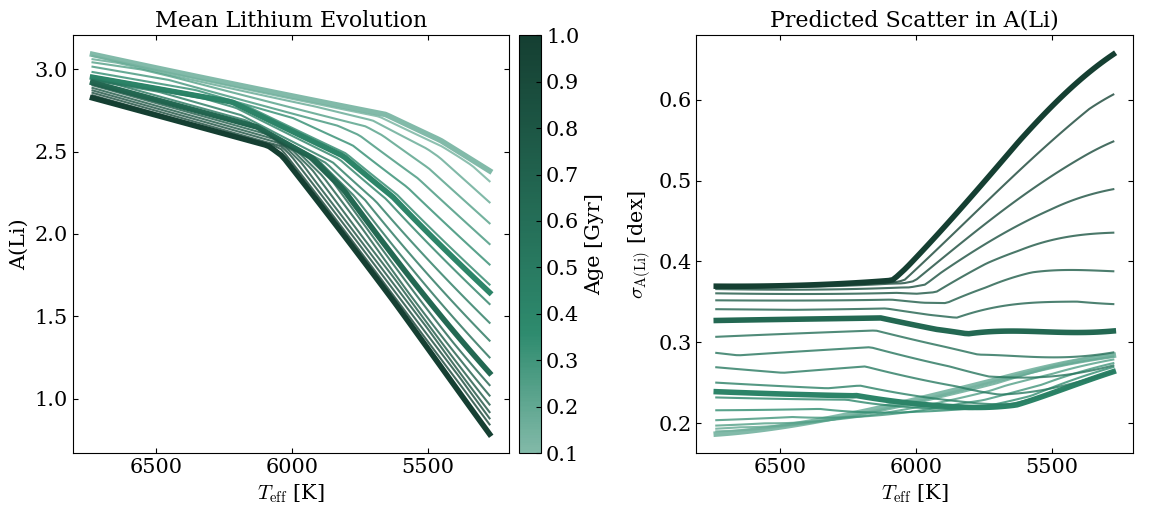

In [17]:
# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.4))

# The lines of all ages, colored by the age, with thick lines for the four cluster ages
for age_val, mean_row, sd_row in zip(ages_band, mean_band, sd_band):
    is_cluster = np.isclose(age_val, age_grid).any()
    ax1.plot(t_grid * 1000, mean_row, color=cmap(norm(age_val)), linewidth=4 if is_cluster else 1.5, alpha=1.0 if is_cluster else 0.8)
    ax2.plot(t_grid * 1000, sd_row, color=cmap(norm(age_val)), linewidth=4 if is_cluster else 1.5, alpha=1.0 if is_cluster else 0.8)

# Labels and titles
ax1.set_xlabel(r'$T_{\rm eff}$ [K]')
ax1.set_ylabel('A(Li)')
ax1.set_title('Mean Lithium Evolution')
ax2.set_xlabel(r'$T_{\rm eff}$ [K]')
ax2.set_ylabel(r'$\sigma_{\rm A(Li)}$ [dex]')
ax2.set_title('Predicted Scatter in A(Li)')
for ax in (ax1, ax2):
    ax.invert_xaxis()

# One colorbar for the age of the left panel, and empty axes of the same width on the right panel
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
colorbar(sm, ax1, label='Age [Gyr]')
make_axes_locatable(ax2).append_axes("right", size="5%", pad=0.1).axis('off')

plt.tight_layout()
plt.show()


The lines change smoothly with the age, and their colors stay in order. The band is also a check of overfitting. Nothing in the data ties the lines between the four ages, so an overfit network would wiggle there. We see no wiggles. If wiggles appeared, we would train for fewer epochs or use a smaller network.

The band shows the physics of lithium depletion that we described at the start. The mean of A(Li) falls toward cooler stars, because the convection zone is deeper there. It also falls with age, because the destruction continues. At 6000 K, the mean falls from about 2.8 at 0.10 Gyr to about 2.4 at 1.00 Gyr. The fall is larger for cooler stars.

The right panel shows the scatter $\sigma_{\rm A(Li)}$. At 6000 K it grows from about 0.2 dex for the young clusters to about 0.4 dex at 1.00 Gyr. For the oldest ages it also grows toward cooler stars. The measurement errors, typically 0.02 to 0.08 dex in A(Li), are small compared with these widths.

Several processes can cause the scatter. A star that rotates faster at the beginning is thought to deplete more lithium by mixing, but we know only its present rotation. Other causes are the magnetic activity, the accretion history and the metallicity. The network cannot separate these causes, so the hidden properties appear as the width and the shape of the mixture.

## Conditional Densities at Three Points

The mean and the standard deviation do not show the shape of the conditional density. We therefore plot the whole conditional density $p(\text{A(Li)}|T_{\rm eff}, \tau)$ at three points.

We choose a hot young point, a solar-type middle-aged point and a cool older point. Each point lies inside the temperature range of the cluster with that age. Each panel shows the following.

- The colored curve is the density of the mixture, the sum of the weighted Gaussians.
- The thin black curves are the weighted components.
- The dashed line marks the mean of the mixture.
- The short vertical lines mark the A(Li) of the stars of that cluster near the temperature.

Hot, young               mixture 3.01 ± 0.20, 12 stars 2.94 ± 0.18
Solar-type, middle-aged  mixture 2.32 ± 0.22, 18 stars 2.28 ± 0.22
Cool, older              mixture 1.60 ± 0.31, 19 stars 1.49 ± 0.28


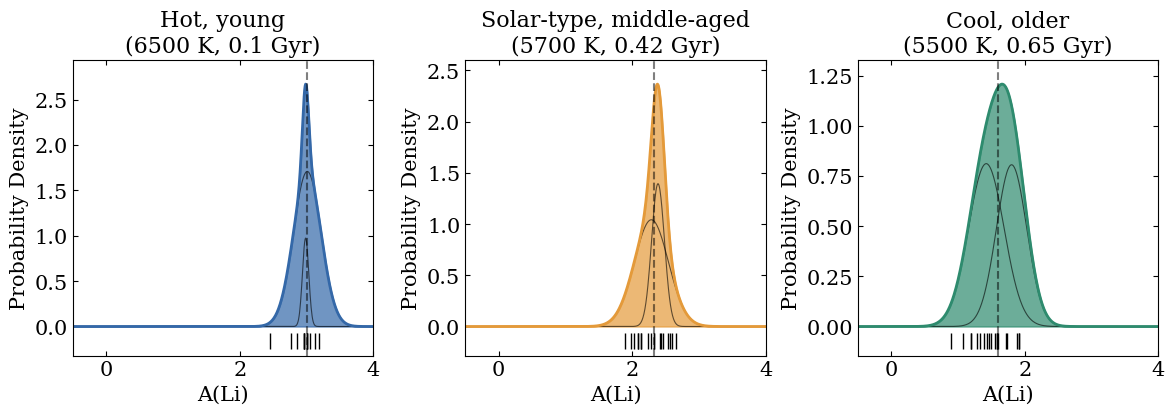

In [18]:
# Select stellar parameters inside the data, with the temperature in units of 1000 K
test_cases = [
    ('Hot, young', 6.5, 0.1),
    ('Solar-type, middle-aged', 5.7, 0.42),
    ('Cool, older', 5.5, 0.65)
]

# A(Li) values for the density, in one column so that it broadcasts against the components
y_grid = torch.linspace(-0.5, 4.0, 600).reshape(-1, 1)

plt.figure(figsize=(12, 4.4))

for i, (name, t_case, age_case) in enumerate(test_cases):
    plt.subplot(1, 3, i + 1)

    # Get the MDN predictions for this case
    X_case = torch.tensor([[t_case, age_case]], dtype=torch.float32)
    with torch.no_grad():
        mu, sigma, pi = model(X_case)
        density = torch.exp(mixture_log_prob(y_grid, mu, sigma, pi)).numpy()
        mean, sd = mixture_moments(mu, sigma, pi)

    # A(Li) of the stars of this cluster within 150 K of the temperature
    near = ALi[(age == age_case) & (np.abs(teff - 1000 * t_case) <= 150)]

    # Plot the density of the mixture, with the weighted component densities as thin lines
    x_range = y_grid.numpy().ravel()
    components = (pi * torch.exp(torch.distributions.Normal(mu, sigma).log_prob(y_grid))).numpy()
    plt.plot(x_range, components, color='black', linewidth=0.8, alpha=0.6)
    plt.fill_between(x_range, density, alpha=0.7, color=f'C{i}')
    plt.plot(x_range, density, linewidth=2, color=f'C{i}')

    # Mark the stars at the bottom and the mean of the mixture
    plt.plot(near, np.full(len(near), -0.06 * density.max()), '|', color='black', markersize=12)
    plt.axvline(mean.item(), color='black', linestyle='--', alpha=0.5)

    # Labels and title
    plt.xlabel('A(Li)')
    plt.ylabel('Probability Density')
    plt.title(f'{name}\n({1000 * t_case:.0f} K, {age_case} Gyr)')
    plt.xlim(-0.5, 4.0)
    plt.ylim(-0.12 * density.max(), 1.1 * density.max())

    # Print the mean and the standard deviation of the mixture and of the stars
    print(f"{name:<24} mixture {mean.item():.2f} ± {sd.item():.2f}, "
          f"{len(near)} stars {near.mean():.2f} ± {near.std():.2f}")

plt.tight_layout()
plt.show()

At the hot young point the density is one narrow peak near 3.0. At the solar-type point the density has a narrow peak near 2.4 and a broad component toward lower A(Li). At the cool older point the density is broad. The width grows from the first point to the last, as the right panel above shows. Each density has one peak, so the stars at a point form one group, and the mixture describes its width and its tail. The mean and the standard deviation of the mixture are close to those of the stars at each point.

## Summary

A standard neural network predicts one value for each input. A Mixture Density Network predicts a density instead. Our main lessons follow.

1. **Conditional density estimation.** An MDN models the conditional density $p(\mathbf{y}|\mathbf{x})$ and not a function $\mathbf{y} = f(\mathbf{x})$. A standard neural network predicts the mean of the outputs, which can lie between two groups of values. An MDN can describe the scatter and several groups of values at one input.
2. **Parameterization by a network.** The network outputs the weights, means and widths of a Gaussian mixture. A softmax keeps the weights positive and summing to 1, and an exponential keeps the widths positive.
3. **Maximum likelihood training.** We minimize the negative log-likelihood by gradient descent, as for other networks. The log-sum-exp function keeps the sum over the components stable.
4. **A probabilistic output.** The mixture gives the mean, the width and the shape of the density at each input. The prediction is a probability density, so it describes the scatter of the data and the mean.
5. **Lithium in open clusters.** The predicted mean of A(Li) falls toward cooler stars and is lower for older clusters. The predicted scatter is larger for older clusters. The predictions change smoothly with the age.

Many quantities in astronomy have a scatter that changes with the inputs or more than one possible value, so a prediction needs a density. The MDN is the basic network model for this case. It shows that a neural network is more than a deterministic mapping from $\mathbf{x}$ to $\mathbf{y}$, because its outputs can define a probability density.